In [54]:
# chargement des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [2]:
# chargement de quelques modules de machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, ColumnTransformer
from imblearn.over_sampling import SMOTE
from mlxtend.plotting import plot_confusion_matrix
from joblib import dump, load
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVR

In [3]:
# chargement du dataset traité pour l'apprentissage automatique
df = pd.read_csv('../../datasets/processed/dec2008-june2017/processed-weather-aus-dec2008-june2017.csv')
# affichage du dataset
df

,location,mintemp,maxtemp,rainfall,evaporation,sunshine,windgustdir,windgustspeed,winddir9am,winddir3pm,...,pressure3pm,cloud9am,cloud3pm,temp9am,temp3pm,raintoday,raintomorrow,year,month,day
0,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,1007.1,8.0,NaN,16.9,21.8,No,No,2008,12,1
1,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,1007.8,NaN,NaN,17.2,24.3,No,No,2008,12,2
2,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,1008.7,NaN,2.0,21.0,23.2,No,No,2008,12,3
3,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,1012.8,NaN,NaN,18.1,26.5,No,No,2008,12,4
4,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,1006.0,7.0,8.0,17.8,29.7,No,No,2008,12,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145273,Uluru,2.8,23.4,0.0,NaN,NaN,E,31.0,SE,ENE,...,1020.3,NaN,NaN,10.1,22.4,No,No,2017,6,21
145274,Uluru,3.6,25.3,0.0,NaN,NaN,NNW,22.0,SE,N,...,1019.1,NaN,NaN,10.9,24.5,No,No,2017,6,22
145275,Uluru,5.4,26.9,0.0,NaN,NaN,N,37.0,SE,WNW,...,1016.8,NaN,NaN,12.5,26.1,No,No,2017,6,23
145276,Uluru,7.8,27.0,0.0,NaN,NaN,SE,28.0,SSE,N,...,1016.5,3.0,2.0,15.1,26.0,No,No,2017,6,24


In [4]:
# description breve du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145278 entries, 0 to 145277
Data columns (total 25 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   location       145278 non-null  object 
 1   mintemp        143975 non-null  float64
 2   maxtemp        144199 non-null  float64
 3   rainfall       142199 non-null  float64
 4   evaporation    82670 non-null   float64
 5   sunshine       75625 non-null   float64
 6   windgustdir    135134 non-null  object 
 7   windgustspeed  135197 non-null  float64
 8   winddir9am     134894 non-null  object 
 9   winddir3pm     141232 non-null  object 
 10  windspeed9am   143693 non-null  float64
 11  windspeed3pm   142398 non-null  float64
 12  humidity9am    142806 non-null  float64
 13  humidity3pm    140953 non-null  float64
 14  pressure9am    130395 non-null  float64
 15  pressure3pm    130432 non-null  float64
 16  cloud9am       89572 non-null   float64
 17  cloud3pm       86102 non-null

In [5]:
# extraction de la variable réponse
Y = df['raintomorrow']
# extraction des variables prédictives
X = df.drop(['raintomorrow'], axis = 1)

In [6]:
# codage numérique de la variable réponse: raintomorrow
Y.replace({'No':0, 'Yes': 1}, inplace = True)

In [8]:
# création des datasets d'entrainement et de test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, stratify = Y, test_size = 0.3, random_state=57)
# dimensions des datasets créés
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((101694, 24), (43584, 24), (101694,), (43584,))

In [9]:
# extraction des variables numériques des prédicteurs d'entrainement
num_cols = X_train.select_dtypes(include = ["int", "float"]).columns
num_cols

Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')

In [10]:
# extraction des variables catégorielles des prédicteurs d'entrainement
cat_cols = X_train.select_dtypes(exclude = "number").columns
cat_cols

Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object')

In [11]:
# construction d'un pipeline générique
def build_pipeline(ml_estimator,
                   num_vars = num_cols, 
                   cat_vars = cat_cols,
                   impute_num = SimpleImputer(strategy="median"), 
                   impute_var = SimpleImputer(strategy="most_frequent"), 
                   scaler_num = StandardScaler(),
                   encoder_cat = OneHotEncoder()):
  # Pipeline de transformation des variables numériques
  numeric_transformer = make_pipeline(
    (impute_num), 
    (scaler_num)
    )
  
  # Pipeline de transformation des variables catégorielles
  categorical_transformer = make_pipeline(
    (impute_var),
    (encoder_cat)
    )
  
  # Combinaison des 2 étapes en un seul objet
  preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_vars),
        ('cat', categorical_transformer, cat_vars)
    ]
    )
  
  # Pipeline final de Machine Learning
  model = Pipeline(steps=[('preprocessing', preprocessor), 
                        ('regressor', ml_estimator)])
  
  return model

In [13]:
# Logistic Regression: Pipeline
pipe_lr = build_pipeline(
                   ml_estimator = LogisticRegression(random_state=None, max_iter=200, class_weight="balanced"),
                   num_vars = num_cols, 
                   cat_vars = cat_cols,
                   impute_num = SimpleImputer(strategy="median"), 
                   impute_var = SimpleImputer(strategy="most_frequent"), 
                   scaler_num = StandardScaler(),
                   encoder_cat = OneHotEncoder()
                   )
# visualisation du pipeline
pipe_lr

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...'cloud3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object'))])),
                ('regressor',
                 LogisticRegression(class_weight='balanced', max_iter=200))])

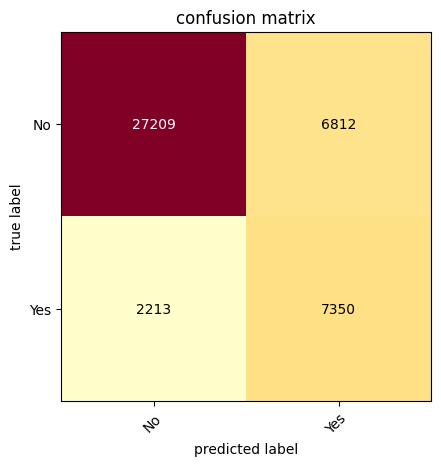

              precision    recall  f1-score   support

           0       0.92      0.80      0.86     34021
           1       0.52      0.77      0.62      9563

    accuracy                           0.79     43584
   macro avg       0.72      0.78      0.74     43584
weighted avg       0.84      0.79      0.81     43584



In [14]:
# Logistic Regression: Estimation
pipe_lr.fit(X_train,Y_train)
predictions = pipe_lr.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

In [36]:
# calcul du ratio entre la classe majoritaire et la classe minoritaire
ratio=Y_train.value_counts()[0]/Y_train.value_counts()[1]
ratio

3.557407905350901

In [43]:
# XGBoost: Pipeline
pipe_xgb = build_pipeline(
                   ml_estimator = XGBClassifier(random_state=None, scale_pos_weight=ratio, n_estimators=100),
                   num_vars = num_cols, 
                   cat_vars = cat_cols,
                   impute_num = SimpleImputer(strategy="median"), 
                   impute_var = SimpleImputer(strategy="most_frequent"), 
                   scaler_num = StandardScaler(),
                   encoder_cat = OneHotEncoder()
                   )
# visualisation du pipeline
pipe_xgb

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...
                               feature_types=None, gamma=None, gpu_id=None,
                               grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, n_estimators=100,
                               n_jobs=None, num_parallel_tree=None,
                               predictor=None, random_state=None, ...))])

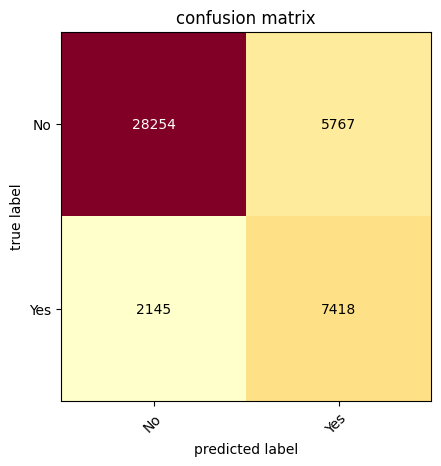

              precision    recall  f1-score   support

           0       0.93      0.83      0.88     34021
           1       0.56      0.78      0.65      9563

    accuracy                           0.82     43584
   macro avg       0.75      0.80      0.76     43584
weighted avg       0.85      0.82      0.83     43584



In [44]:
# XGBoost: Estimation
pipe_xgb.fit(X_train,Y_train)
predictions = pipe_xgb.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

In [ ]:
# entrainement des deux modèles sur le dataset entier

In [45]:
# création des datasets d'entrainement et de test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.000001, random_state=42)
# dimensions des datasets créés
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((145277, 24), (1, 24), (145277,), (1,))

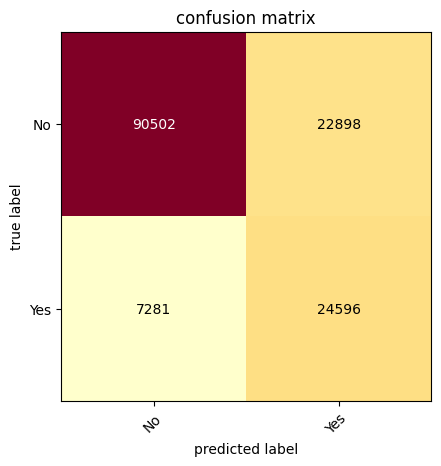

              precision    recall  f1-score   support

           0       0.93      0.80      0.86    113400
           1       0.52      0.77      0.62     31877

    accuracy                           0.79    145277
   macro avg       0.72      0.78      0.74    145277
weighted avg       0.84      0.79      0.81    145277



In [47]:
# Logistic Regression: Estimation
pipe_lr.fit(X_train,Y_train)
predictions = pipe_lr.predict(X_train)
cm=confusion_matrix(Y_train, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_train, predictions))
# print(accuracy_score(Y_test, predictions))

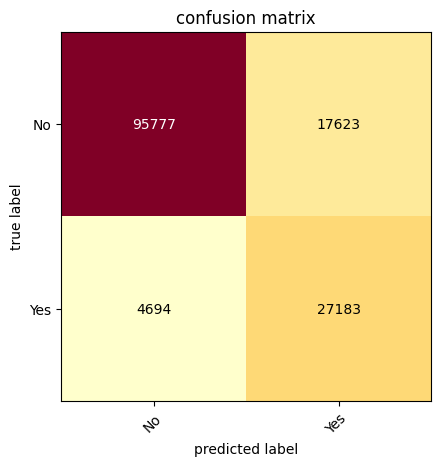

              precision    recall  f1-score   support

           0       0.95      0.84      0.90    113400
           1       0.61      0.85      0.71     31877

    accuracy                           0.85    145277
   macro avg       0.78      0.85      0.80    145277
weighted avg       0.88      0.85      0.85    145277



In [49]:
# XGBoost: Estimation
pipe_xgb.fit(X_train,Y_train)
predictions = pipe_xgb.predict(X_train)
cm=confusion_matrix(Y_train, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_train, predictions))
# print(accuracy_score(Y_test, predictions))

In [ ]:
# le modèle basé sur l'algorithme XGBoost semble être le meilleur sur tout le dataset d'entrainement

In [56]:
# sauvegarde du modèle meilleur sélectionné
path = '../../models/final-model-pipe-xgb' + datetime.now().strftime('-%Y-%m-%d-%H-%M-%S') + '.pkl'
pickle.dump(pipe_xgb, open(path, 'wb'))

In [60]:
# chargement du modèle sauvegardé
path='../../models/final-model-pipe-xgb-2023-05-26-02-05-05.pkl'
pickled_model = pickle.load(open(path, 'rb'))
# utilisation du modèle chargé
pickled_model.predict(X_test)
# vraie classe
#print(Y_test)

array([0])

In [73]:
# liste de toutes les variables prédictives
X.columns

Index(['location', 'mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustdir', 'windgustspeed', 'winddir9am', 'winddir3pm',
       'windspeed9am', 'windspeed3pm', 'humidity9am', 'humidity3pm',
       'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm', 'temp9am',
       'temp3pm', 'raintoday', 'year', 'month', 'day'],
      dtype='object')

In [74]:
# liste des variables numériques
num_cols

Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm',
       'temp9am', 'temp3pm', 'year', 'month', 'day'],
      dtype='object')

In [75]:
# liste des variables catégorielles
cat_cols

Index(['location', 'windgustdir', 'winddir9am', 'winddir3pm', 'raintoday'], dtype='object')

In [76]:
# modalités de la variable catégorielle: location
X['location'].unique()

array(['Albury', 'BadgerysCreek', 'Cobar', 'CoffsHarbour', 'Moree',
       'Newcastle', 'NorahHead', 'NorfolkIsland', 'Penrith', 'Richmond',
       'Sydney', 'SydneyAirport', 'WaggaWagga', 'Williamtown',
       'Wollongong', 'Canberra', 'Tuggeranong', 'MountGinini', 'Ballarat',
       'Bendigo', 'Sale', 'MelbourneAirport', 'Melbourne', 'Mildura',
       'Nhil', 'Portland', 'Watsonia', 'Dartmoor', 'Brisbane', 'Cairns',
       'GoldCoast', 'Townsville', 'Adelaide', 'MountGambier', 'Nuriootpa',
       'Woomera', 'Albany', 'Witchcliffe', 'PearceRAAF', 'PerthAirport',
       'Perth', 'SalmonGums', 'Walpole', 'Hobart', 'Launceston',
       'AliceSprings', 'Darwin', 'Katherine', 'Uluru'], dtype=object)

In [77]:
# modalités de la variable catégorielle: windgustdir
X['windgustdir'].unique()

array(['W', 'WNW', 'WSW', 'NE', 'NNW', 'N', 'NNE', 'SW', nan, 'ENE',
       'SSE', 'S', 'NW', 'SE', 'ESE', 'E', 'SSW'], dtype=object)

In [78]:
# modalités de la variable catégorielle: winddir9am
X['winddir9am'].unique()

array(['W', 'NNW', 'SE', 'ENE', 'SW', 'SSE', 'S', 'NE', nan, 'SSW', 'N',
       'WSW', 'ESE', 'E', 'NW', 'WNW', 'NNE'], dtype=object)

In [79]:
# modalités de la variable catégorielle: winddir3pm
X['winddir3pm'].unique()

array(['WNW', 'WSW', 'E', 'NW', 'W', 'SSE', 'ESE', 'ENE', 'NNW', 'SSW',
       'SW', 'SE', 'N', 'S', 'NNE', nan, 'NE'], dtype=object)

In [80]:
# modalités de la variable catégorielle: raintoday
X['raintoday'].unique()

array(['No', 'Yes', nan], dtype=object)